### Семинар 9

# Тема: Масштабирование (нормализация) данных. Применение конвейера.

Масштабирование (нормализация) признаков - линейное преобразование столбцов матрицы признаков. Масштабирование признаков не меняет структуру данных. 

Масштабирование признаков относится к методам предобработки данных. Её необходимо производить в связи с тем, что многие алгоритмы машинного обучения лучше работают, когда все признаки масштабированы. Для алгоритмов, где применяется метод градиентного спуска, в случае масштабирования данных он сходится быстрее. Иногда при масштабировании признаков метрики качества немного улучшаются. Деревья и леса представляют собой два алгоритма из очень немногих, где не нужно масштабировать данные. Для таких алгоритмов, которые работают независимо от масштаба признаков, хуже от нормализации обычно не становится. 

Масштабирование применяется только к числовым признакам. Масштабируют только признаки, но не целевую переменную. Существует целый ряд методов масштабирования. Рассмотрим два из них.

## min-max нормализация

`min-max` нормализация приводит каждый признак к значению между 0 и 1 или от a до b.  
Каждый признак `x` трансформируется по формуле: $${x_i}^{norm} := \frac{x_i - x_{min}}{x_{max} - x_{min}}$$

$${x_i}^{norm} := a+\frac{(x_i - x_{min})(b-a)}{x_{max} - x_{min}}$$

Класс `MinMaxScale`из библиотеки `sklearn` имеет метод `fit` для вычисления минимального ($x_{min}$) и максимального ($x_{max}$) значения признака, а метод `transform` преобразует признак по формуле. Можно выполнить обе этих операции сразу так `fit_transform`:

```python
  from sklearn.preprocessing import MinMaxScaler
  scaler = MinMaxScaler(feature_range=(0, 1))# по умолчанию диапазон от 0 до 1
  scaler.fit_transform(X_train)
  scaler.transform(X_test)
```
Важно понимать, что масштабирование производится после разделения на обучающую и тестовую части, при этом, при преобразовании тестовых данных, следует использовать минимальные и максимальные значения признаков, полученные на обучающих данных. Если мы сразу отмасштабируем все данные (и обучающую, и тестовую выборки), то информация из тестовой части «утечет» в обучающую просто потому, что в минимальные и максимальные значения признаков рассчитаны на основе всех данных. Как следствие, модель на этапе обучения уже «увидит» тестовые данные, а значит качество модели «на тесте» может быть неоправданно завышено.
## std нормализация (стандартная нормализация)

`std` нормализация приводит каждый признак к виду нормального распределения, когда он имеет среднее значение 0 и стандартное отклонение 1.  
Каждый признак `x` трансформируется по формуле: $${x_i}^{st} := \frac{x_i - x_{mean}}{x_{std}}$$

Класс `StandardScaler`из библиотеки `sklearn` имеет метод `fit` для вычисления среднего значения ($x_{mean}$) признака и его стандартного отклонения ($x_{std}$), а метод `transform` преобразует признак по формуле. Можно выполнить обе этих операции сразу так `fit_transform`:

```python
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
scaler.fit_transform(X_train)
scaler.transform(X_test)
```

Нормализация min-max предпочтительна, когда данные не соответствуют гауссовскому (нормальному) распределению. Нормализация min-max предпочтительна для алгоритмов, которые не следуют какому-либо распределению. Обратите внимание, что на min-max нормализацию влияют выбросы.

С другой стороны, стандартная нормализация может быть полезна в тех случаях, когда данные подчиняются распределению Гаусса. Однако это не обязательно. Кроме того, в отличие от min-max нормализации, стандартная нормализация не имеет ограничивающего диапазона. Это означает, что даже если в данных есть выбросы, стандартизация на них не повлияет.

### Применение конвейера

Класс Pipeline позволяет писать более лаконичный код и уменьшает вероятность ошибок, которые могут быть допущены при построении цепочек операций без использования класса Pipeline (например, мы можем забыть применить преобразования к тестовому набору или можем применить их в неправильном порядке).

```python
from sklearn.pipeline import Pipeline
pipe = Pipeline(steps = [('scaler', MinMaxScaler()), ('lr', LogisticRegression())])
pipe.fit(X_train, y_train)
y_test_pred=pipe.predict(X_test)
```

Класс make_pipeline - конвейер c автоматическим присваиванием имени каждому этапу.

```python
from sklearn.pipeline import make_pipeline
pipe_quick = make_pipeline(StandardScaler(), LinearRegression())
pipe_quick.fit(X_train, y_train)
y_test_pred=pipe_quick.predict(X_test)
```

Импортируем необходимые библиотеки:

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing, load_breast_cancer
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn import metrics

from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.pipeline import Pipeline, make_pipeline

# Задания для выполнения:

### 1. Загрузите встроенный набор данных о диагностике рака молочной железы. Выведите описание датасета. Обозначьте за `X` данные, а за `y` целевую переменную. Выведите их размеры.

In [2]:
data = load_breast_cancer()
type(data)

sklearn.utils._bunch.Bunch

In [3]:
X, y = data.data, data.target
X.shape, y.shape

((569, 30), (569,))

In [4]:
print(data.DESCR)

.. _breast_cancer_dataset:

Breast cancer Wisconsin (diagnostic) dataset
--------------------------------------------

**Data Set Characteristics:**

:Number of Instances: 569

:Number of Attributes: 30 numeric, predictive attributes and the class

:Attribute Information:
    - radius (mean of distances from center to points on the perimeter)
    - texture (standard deviation of gray-scale values)
    - perimeter
    - area
    - smoothness (local variation in radius lengths)
    - compactness (perimeter^2 / area - 1.0)
    - concavity (severity of concave portions of the contour)
    - concave points (number of concave portions of the contour)
    - symmetry
    - fractal dimension ("coastline approximation" - 1)

    The mean, standard error, and "worst" or largest (mean of the three
    worst/largest values) of these features were computed for each image,
    resulting in 30 features.  For instance, field 0 is Mean Radius, field
    10 is Radius SE, field 20 is Worst Radius.

    - 

In [5]:
pd.DataFrame(X, columns=data.feature_names).head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [6]:
pd.Series(y).value_counts()

1    357
0    212
Name: count, dtype: int64

### 2. Разделите данные на обучающую и тестовую части. Выведите их размеры.  Постройте модель логистической регрессии для предсказания наличия заболевания. Выведите, полученные коэффициенты  гиперплоскости. Сделайте предсказание на тестовых данных. Вычислите метрики accuracy и F1-меру. Сделайте вывод о качестве работы модели логистической регрессии для этих данных. 

In [7]:
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42)
X_train.shape[0], X_test.shape[0]

(426, 143)

In [8]:
model = LogisticRegression(max_iter=10000)
model.fit(X_train, y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",10000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use 

In [9]:
model.intercept_, model.coef_

(array([31.47101099]),
 array([[ 1.08746833e+00,  2.34962507e-01, -4.24071010e-01,
          2.86295438e-02, -1.38405138e-01, -2.47326773e-01,
         -5.22231475e-01, -2.73322816e-01, -2.16626728e-01,
         -4.09612156e-02, -1.25132562e-01,  1.43206112e+00,
          3.96531923e-01, -1.42923296e-01, -1.89571750e-02,
         -1.95387055e-04, -7.45638571e-02, -3.41372535e-02,
         -4.46282440e-02, -9.05825327e-05,  1.05138674e-01,
         -5.13518419e-01, -3.99532097e-02, -1.35324324e-02,
         -2.81446397e-01, -7.70386460e-01, -1.38808839e+00,
         -4.89570399e-01, -7.24130007e-01, -1.07817238e-01]]))

In [10]:
y_test_pred = model.predict(X_test)
accuracy = metrics.accuracy_score(y_test, y_test_pred)
accuracy

0.965034965034965

In [11]:
f1 = metrics.f1_score(y_test, y_test_pred)
f1

0.9720670391061452

### 3. Напишите самостоятельно класс MinMax_Scaler, который имеет два атрибута и два метода. Атрибуты - это массивы минимальных и максимальных значений по каждому столбцу матрицы признаков. Первый метод fit принимает матрицу признаков и вычисляет массивы минимальных и максимальных значений по каждому признаку, а второй метод transform преобразует элементы столбцов по соответствующей min-max нормализации формуле. Преобразуйте при помощи этого класса обучающие и тестовые данные.

Формула для min-max нормализации имеет вид  ${x_i}^{norm} := \frac{x_i - x_{min}}{x_{max} - x_{min}}$.

In [12]:
class MinMax_Scaler():
    def __init__(self):
        self.min_ = None
        self.max_ = None
    
    def fit(self, X):
        self.min_ = X.min(axis=0)
        self.max_ = X.max(axis=0)
        
    def transform(self, X):
        return (X - self.min_) / (self.max_ - self.min_)

In [13]:
sc = MinMax_Scaler()
sc.fit(X_train)
sc.min_, sc.max_

(array([7.691e+00, 9.710e+00, 4.792e+01, 1.704e+02, 5.263e-02, 1.938e-02,
        0.000e+00, 0.000e+00, 1.167e-01, 4.996e-02, 1.115e-01, 3.602e-01,
        7.570e-01, 6.802e+00, 1.713e-03, 2.252e-03, 0.000e+00, 0.000e+00,
        7.882e-03, 8.948e-04, 8.678e+00, 1.202e+01, 5.449e+01, 2.236e+02,
        7.117e-02, 2.729e-02, 0.000e+00, 0.000e+00, 1.565e-01, 5.504e-02]),
 array([2.811e+01, 3.928e+01, 1.885e+02, 2.501e+03, 1.634e-01, 3.114e-01,
        4.268e-01, 2.012e-01, 3.040e-01, 9.744e-02, 2.873e+00, 4.885e+00,
        2.198e+01, 5.422e+02, 3.113e-02, 1.354e-01, 3.960e-01, 5.279e-02,
        6.146e-02, 2.984e-02, 3.604e+01, 4.954e+01, 2.512e+02, 4.254e+03,
        2.184e-01, 9.379e-01, 9.608e-01, 2.910e-01, 6.638e-01, 1.730e-01]))

In [14]:
X_train_sc = sc.transform(X_train)
X_test_sc = sc.transform(X_test)

pd.DataFrame(X_train_sc, columns=data.feature_names).head(3)

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,0.254616,0.115320,0.241642,0.148245,0.152749,0.061331,0.052952,0.058201,0.090763,0.123210,...,0.180615,0.093817,0.167302,0.087684,0.169734,0.095991,0.123439,0.184399,0.146659,0.119617
1,0.279593,0.365573,0.289657,0.165751,0.523337,0.436682,0.338566,0.406163,0.506674,0.490522,...,0.282582,0.470149,0.298968,0.154029,0.585682,0.393483,0.531432,0.704811,0.398186,0.473550
2,0.258044,0.290159,0.257931,0.152235,0.188499,0.204130,0.095056,0.093588,0.377469,0.190185,...,0.199254,0.335554,0.212597,0.098824,0.150241,0.224586,0.166944,0.227079,0.323674,0.147762


In [15]:
pd.DataFrame(X_train, columns=data.feature_names).head(3)

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,12.89,13.12,81.89,515.9,0.06955,0.03729,0.02260,0.01171,0.1337,0.05581,...,13.62,15.54,87.40,577.0,0.09616,0.1147,0.1186,0.05366,0.2309,0.06915
1,13.40,20.52,88.64,556.7,0.11060,0.14690,0.14450,0.08172,0.2116,0.07325,...,16.41,29.66,113.30,844.4,0.15740,0.3856,0.5106,0.20510,0.3585,0.11090
2,12.96,18.29,84.18,525.2,0.07351,0.07899,0.04057,0.01883,0.1874,0.05899,...,14.13,24.61,96.31,621.9,0.09329,0.2318,0.1604,0.06608,0.3207,0.07247


### 4. Добавьте в класс, написанный в предыдущем задании, метод fit_transform, который принимает матрицу признаков и сразу вычисляет массивы минимальных и максимальных значений по каждому признаку, а также преобразует элементы столбцов мартицы признаков по соответствующей min-max нормализации формуле. Преобразуйте при помощи этого класса обучающие и тестовые данные.

In [16]:
class Min_Max_Scaler():
    def __init__(self):
        self.min_ = None
        self.max_ = None
    
    def fit(self, X):
        self.min_ = X.min(axis=0)
        self.max_ = X.max(axis=0)
        
    def transform(self, X):
        return (X - self.min_) / (self.max_ - self.min_)

    def fit_transform(self, X):
        self.fit(X)
        return self.transform(X)

In [17]:
scal = Min_Max_Scaler()
X_train_scal = scal.fit_transform(X_train)
X_test_scal = scal.transform(X_test)
X_train_scal[:2]

array([[0.2546158 , 0.11531958, 0.24164177, 0.14824509, 0.15274894,
        0.06133142, 0.0529522 , 0.0582008 , 0.09076348, 0.12320977,
        0.01510049, 0.02404526, 0.01686849, 0.01097875, 0.10259374,
        0.0841019 , 0.04171717, 0.11185831, 0.15506365, 0.04098089,
        0.18061545, 0.09381663, 0.16730212, 0.0876836 , 0.16973443,
        0.0959906 , 0.1234388 , 0.18439863, 0.14665878, 0.11961682],
       [0.27959254, 0.36557322, 0.28965713, 0.16575131, 0.52333664,
        0.43668242, 0.33856607, 0.40616302, 0.50667379, 0.49052233,
        0.10106826, 0.12606082, 0.11006926, 0.05018323, 0.12581161,
        0.15319795, 0.08717172, 0.25269937, 0.17111501, 0.10745132,
        0.28258168, 0.47014925, 0.29896802, 0.15402938, 0.58568227,
        0.39348349, 0.53143214, 0.704811  , 0.39818648, 0.47355036]])

### 5. Убедитесь, что у масштабированных при помощи min-max нормализации обучающих данных минимальное значение каждого признака стало равно 0, а максимальное 1. А у масштабированных тестовых данных это не совсем так.

In [18]:
X_train_scal.min(axis=0)

array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.])

In [19]:
X_train_scal.max(axis=0)

array([1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.])

In [20]:
X_test_scal.min(axis=0)

array([-0.03477154,  0.0226581 , -0.02937829, -0.01154209,  0.1185339 ,
        0.05547565,  0.        ,  0.        , -0.0571276 ,  0.05686605,
        0.00184682,  0.00057461,  0.00067851,  0.00402131,  0.04949519,
        0.02556554,  0.        ,  0.        ,  0.03092687,  0.01120048,
       -0.02733718,  0.01252665, -0.02074119, -0.00952759,  0.11424302,
        0.03036426,  0.        ,  0.        ,  0.00019712,  0.03399457])

In [21]:
X_test_scal.max(axis=0)

array([0.85846516, 0.72404464, 0.87907241, 0.73268686, 0.76257109,
       1.11643038, 0.87956888, 0.91699801, 0.92845702, 0.68386689,
       0.42712294, 0.7814268 , 0.41831975, 0.36028898, 0.48703131,
       0.78219725, 0.76717172, 0.62928585, 1.32643996, 0.75885466,
       0.87025802, 0.93656716, 0.81088913, 0.79605002, 1.02852679,
       1.13188961, 1.30308077, 0.9975945 , 0.76384782, 1.29247202])

### 6. Осуществите масштабирование признаков методом min-max при помощи библиотечной функции. Убедитесь, что они будут теми же, что и при масштабировании вручную.

In [22]:
scaler = MinMaxScaler()
scaler.fit(X_train)
scaler.data_min_,scaler.data_max_

(array([7.691e+00, 9.710e+00, 4.792e+01, 1.704e+02, 5.263e-02, 1.938e-02,
        0.000e+00, 0.000e+00, 1.167e-01, 4.996e-02, 1.115e-01, 3.602e-01,
        7.570e-01, 6.802e+00, 1.713e-03, 2.252e-03, 0.000e+00, 0.000e+00,
        7.882e-03, 8.948e-04, 8.678e+00, 1.202e+01, 5.449e+01, 2.236e+02,
        7.117e-02, 2.729e-02, 0.000e+00, 0.000e+00, 1.565e-01, 5.504e-02]),
 array([2.811e+01, 3.928e+01, 1.885e+02, 2.501e+03, 1.634e-01, 3.114e-01,
        4.268e-01, 2.012e-01, 3.040e-01, 9.744e-02, 2.873e+00, 4.885e+00,
        2.198e+01, 5.422e+02, 3.113e-02, 1.354e-01, 3.960e-01, 5.279e-02,
        6.146e-02, 2.984e-02, 3.604e+01, 4.954e+01, 2.512e+02, 4.254e+03,
        2.184e-01, 9.379e-01, 9.608e-01, 2.910e-01, 6.638e-01, 1.730e-01]))

In [23]:
X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)
X_train_scaled[:1]

array([[0.2546158 , 0.11531958, 0.24164177, 0.14824509, 0.15274894,
        0.06133142, 0.0529522 , 0.0582008 , 0.09076348, 0.12320977,
        0.01510049, 0.02404526, 0.01686849, 0.01097875, 0.10259374,
        0.0841019 , 0.04171717, 0.11185831, 0.15506365, 0.04098089,
        0.18061545, 0.09381663, 0.16730212, 0.0876836 , 0.16973443,
        0.0959906 , 0.1234388 , 0.18439863, 0.14665878, 0.11961682]])

### 7. Изобразите гистограммы признаков до и после min-max масштабирования.

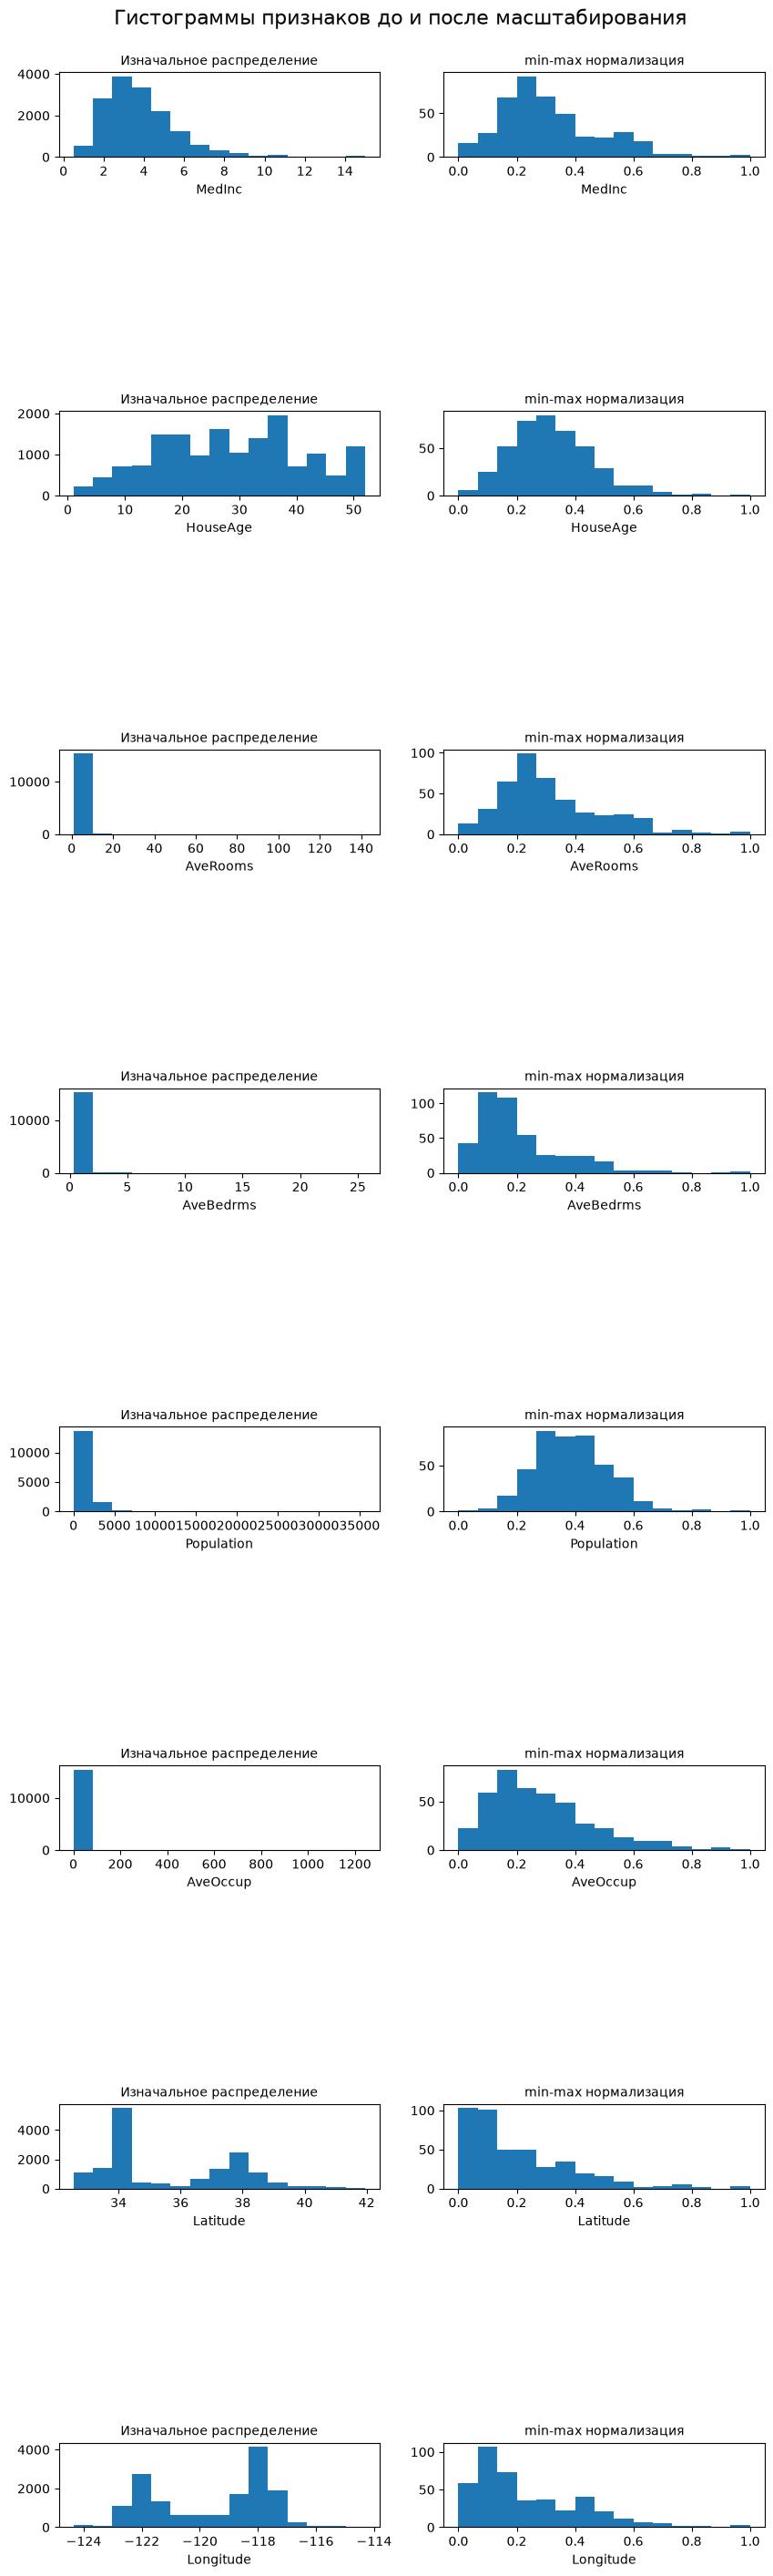

In [79]:
f, ax = plt.subplots(nrows = X_train.shape[1], ncols = 2, figsize=(10,35))
f.suptitle("Гистограммы признаков до и после масштабирования",y = 0.9,fontsize=16)
for i in range(0,X_train.shape[1]):
    ax[i][0].hist(X_train[:, i], bins = 15)
    ax[i][0].set_title('Изначальное распределение',fontsize=10)
    ax[i][0].set_xlabel(data.feature_names[i])
    
    ax[i][1].hist(X_train_scaled[:, i], bins = 15)
    ax[i][1].set_title('min-max нормализация',fontsize=10)
    ax[i][1].set_xlabel(data.feature_names[i])
f.subplots_adjust(hspace=3)

plt.show()

### 8. Обучите модель логистической регрессии (не добавляя итерации) для предсказания наличия заболевания на масштабированных данных методом min-max. Выведите полученные коэффициенты  гиперплоскости. Выведите названия признаков рядом с соответствующими значениями коэффициентов, определите наиболее значимые признаки.

In [25]:
model_ln = LogisticRegression()

In [26]:
model_ln.fit(X_train_scaled, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

In [27]:
model_ln.coef_, model_ln.intercept_

(array([[-1.71621643, -1.64503237, -1.66284027, -1.42740759, -0.64636508,
         -0.26043664, -1.2041863 , -1.95065969, -0.48553724,  0.84804835,
         -1.14524077, -0.06695901, -0.83567697, -0.74483001, -0.038253  ,
          0.64176641,  0.23509085, -0.25380244,  0.22970929,  0.63492818,
         -2.13131088, -2.21110139, -1.8814488 , -1.50831071, -1.37435871,
         -0.6705115 , -1.56588316, -2.33010655, -1.32465885, -0.20716885]]),
 array([8.23955273]))

In [28]:
pd.DataFrame(np.abs(model_ln.coef_[0]), data.feature_names, columns=['coef']).sort_values(by='coef', ascending=False)

,coef
worst concave points,2.330107
worst texture,2.211101
worst radius,2.131311
mean concave points,1.950660
worst perimeter,1.881449
mean radius,1.716216
mean perimeter,1.662840
mean texture,1.645032
worst concavity,1.565883
worst area,1.508311


### 9. Сделайте предсказание на масштабированных методом min-max тестовых данных. Вычислите метрики accuracy и F1-меру. Изменились ли значения метрик при масштабировании данных?.

In [29]:
accuracy

0.965034965034965

In [30]:
f1

0.9720670391061452

In [31]:
y_test_pred_scaled = model_ln.predict(X_test_scaled)
accuracy_scaled, f1_scaled = metrics.accuracy_score(y_test, y_test_pred_scaled), metrics.f1_score(y_test, y_test_pred_scaled)
accuracy_scaled, f1_scaled

(0.9790209790209791, 0.9832402234636871)

### 10. Обучите модель логистической регрессии на масштабированных данных методом min-max нормализации с применением конвейера, используя класс Pipeline. Выведите полученные коэффициенты гиперплоскости. Сделайте предсказание на масштабированных тестовых данных и вычислите метрики.

In [32]:
pipe = Pipeline(steps =[('scaler', MinMaxScaler()),('model', LogisticRegression())])
pipe

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"feature_range feature_range: tuple (min, max), default=(0, 1)Desired range of transformed data.","(0, ...)"
,"copy copy: bool, default=TrueSet to False to perform inplace row normalization and avoid acopy (if the input is already a numpy array).",True
,"clip clip: bool, default=FalseSet to True to clip transformed values of held-out data toprovided `feature_range`.Since this parameter will clip values, `inverse_transform` may notbe able to restore the original data... note:: Setting `clip=True` does not prevent feature drift (a distribution shift between training and test data). The transformed values are clipped to the `feature_range`, which helps avoid unintended behavior in models sensitive to out-of-range inputs (e.g. linear models). Use with care, as clipping can distort the distribution of test data... versionadded:: 0.24",False
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio 

In [33]:
pipe.fit(X_train, y_train)
pipe.named_steps['model'].intercept_, pipe.named_steps['model'].coef_

(array([8.23955273]),
 array([[-1.71621643, -1.64503237, -1.66284027, -1.42740759, -0.64636508,
         -0.26043664, -1.2041863 , -1.95065969, -0.48553724,  0.84804835,
         -1.14524077, -0.06695901, -0.83567697, -0.74483001, -0.038253  ,
          0.64176641,  0.23509085, -0.25380244,  0.22970929,  0.63492818,
         -2.13131088, -2.21110139, -1.8814488 , -1.50831071, -1.37435871,
         -0.6705115 , -1.56588316, -2.33010655, -1.32465885, -0.20716885]]))

In [34]:
y_test_pred_pipe = pipe.predict(X_test)
y_test_pred_pipe[:5]

array([1, 0, 0, 1, 1])

In [35]:
metrics.accuracy_score(y_test, y_test_pred_pipe), accuracy_scaled

(0.9790209790209791, 0.9790209790209791)

In [36]:
metrics.f1_score(y_test, y_test_pred_pipe), f1_scaled

(0.9832402234636871, 0.9832402234636871)

# Задания для самостоятельного выполнения:

### 1. Загрузите встроенные данные о показателе медианной стоимости дома в округах Калифорнии. Выведите описание датасета. Обозначьте за _X_ данные, а за _y_ целевую переменную. Выведите их размеры.

In [37]:
data = fetch_california_housing()
type(data)

sklearn.utils._bunch.Bunch

In [38]:
print(data.DESCR)

.. _california_housing_dataset:

California Housing dataset
--------------------------

**Data Set Characteristics:**

:Number of Instances: 20640

:Number of Attributes: 8 numeric, predictive attributes and the target

:Attribute Information:
    - MedInc        median income in block group
    - HouseAge      median house age in block group
    - AveRooms      average number of rooms per household
    - AveBedrms     average number of bedrooms per household
    - Population    block group population
    - AveOccup      average number of household members
    - Latitude      block group latitude
    - Longitude     block group longitude

:Missing Attribute Values: None

This dataset was obtained from the StatLib:
https://lib.stat.cmu.edu/datasets/houses.zip

The target variable is the median house value for California districts,
expressed in hundreds of thousands of dollars ($100,000).

This dataset was derived from the 1990 U.S. census, using one row per census
block group. A block g

In [39]:
X, y = data.data, data.target
X.shape, y.shape

((20640, 8), (20640,))

### 2. Разделите данные на обучающую и тестовую части. Выведите их размеры. Постройте модель линейной регрессии для предсказания медианной стоимости дома в округах Калифорнии. Выведите, полученные коэффициенты  гиперплоскости. Сделайте предсказание на тестовых данных. Вычислите метрики: коэффициент детерминации и ошибка RMSE. Сделайте вывод о качестве работы модели линейной регрессии для этих данных. 

In [40]:
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42)
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((15480, 8), (5160, 8), (15480,), (5160,))

In [41]:
model = LinearRegression()
model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](8,)","[ 0.45, 0.01,-0.12,...,-0. ,-0.42,-0.43]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-37.03
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,8
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(8)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](8,)","[142198.1 , 1523.95, 1461.4 ,..., 213.27, 62.33, 20.45]"


In [42]:
model.intercept_, model.coef_

(np.float64(-37.02782758526916),
 array([ 4.47600069e-01,  9.56752596e-03, -1.24755956e-01,  7.94471254e-01,
        -1.43902596e-06, -3.44307993e-03, -4.18555257e-01, -4.33405135e-01]))

In [43]:
y_pred = model.predict(X_test)
y_pred

array([0.72412832, 1.76677807, 2.71151581, ..., 1.72382152, 2.34689276,
       3.52917352], shape=(5160,))

In [44]:
r2 = metrics.r2_score(y_test, y_pred)
r2

0.5910509795491358

In [45]:
rmse = metrics.root_mean_squared_error(y_test, y_pred)
rmse

0.7356145375446763

### 3. Напишите самостоятельно класс Standard_Scaler, который имеет два атрибута и три метода. Атрибуты - это массивы средних значений и средних квадратических отклонений по каждому столбцу матрицы признаков. Первый метод fit принимает матрицу признаков и вычисляет массивы средних значений и средних квадратических отклонений по каждому признаку, а второй метод transform преобразует элементы столбцов по соответствующей формуле стандартной нормализации. Третий метод fit_transform, принимает матрицу признаков и сразу вычисляет массивы средних значений и средних квадратических отклонений, а также преобразует элементы столбцов мартицы признаков по соответствующей формуле. Преобразуйте при помощи этого класса обучающие и тестовые данные.

Формула для стандартной нормализации имеет вид: ${x_i}^{norm} := \frac{x_i - x_{mean}}{x_{std}}$.

In [46]:
class Standard_Scaler():
    def __init__(self):
        self.mean_ = None
        self.std_ = None
    
    def fit(self, X):
        self.mean_ = X.mean(axis=0)
        self.std_ = X.std(axis=0)
        
    def transform(self, X):
        return (X - self.mean_)/self.std_
        
    def fit_transform(self, X):
        self.fit(X)
        return self.transform(X)

In [47]:
sc = Standard_Scaler()
X_train_sc = sc.fit_transform(X_train)
X_train_sc

array([[ 0.17648852,  0.66640687, -0.06085431, ..., -0.04828325,
        -0.8607415 ,  0.73099911],
       [ 0.77137436,  1.06288858,  0.38352076, ..., -0.05872947,
         0.70916822, -1.19670983],
       [ 0.02142423,  0.58711053,  0.27852339, ..., -0.07283798,
         1.31370062, -1.55128842],
       ...,
       [-0.49582442,  0.58711053, -0.5983225 , ...,  0.01885405,
        -0.75764295,  0.60115343],
       [ 0.96699069, -1.07811266,  0.39633361, ...,  0.0060417 ,
         0.90599273, -1.1867217 ],
       [-0.68434939,  1.855852  , -0.83954627, ..., -0.08347358,
         0.99503238, -1.41644868]], shape=(15480, 8))

In [48]:
X_test_sc = sc.transform(X_test)
X_test_sc

array([[-1.15411223, -0.28514924, -0.51346718, ...,  0.06447083,
         0.19367548,  0.28652736],
       [-0.70756701,  0.11133247, -0.16361884, ..., -0.03570466,
        -0.23746391,  0.06179445],
       [-0.20917611,  1.855852  , -0.6022714 , ..., -0.14606959,
         1.00909127, -1.4264368 ],
       ...,
       [-0.89908611,  0.66640687, -0.89340574, ...,  0.12360294,
        -0.76232924,  0.66108221],
       [ 1.58036659, -1.79177974,  0.80393479, ..., -0.04836253,
         1.34181841, -0.73725589],
       [ 1.44652384,  0.58711053,  0.12349223, ..., -0.04755791,
        -0.82325111,  0.5911653 ]], shape=(5160, 8))

### 4. Убедитесь, что у стандартизированных обучающих данных среднее значение стало равно 0, а стандартное отклонение равно 1. А у масштабированных тестовых данных среднее значение стало близко к 0, а стандартное отклонение близко к 1.

In [49]:
X_train_sc.mean(axis=0).round(5), X_train_sc.std(axis=0)

(array([-0., -0.,  0., -0., -0., -0.,  0., -0.]),
 array([1., 1., 1., 1., 1., 1., 1., 1.]))

In [78]:
X_test_sc.mean(axis=0), X_test_sc.std(axis=0).round(5)

(array([-0.01605928,  0.0137949 , -0.01089978, -0.00187801, -0.00707167,
        -0.01204623, -0.02785199,  0.02802935]),
 array([0.99158, 0.99176, 1.08415, 1.29063, 0.96285, 0.13604, 1.00349,
        1.00191]))

### 5. Осуществите стандартизацию признаков при помощи библиотечных функций. Убедитесь, что они будут теми же, что и при стандартизации вручную.
Указание: Создайте объект класса [StandardScaler](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html). Примените к нему метод _fit_, передав в него обучающие данные, он рассчитает среднее арифметическое и среднее квадратическое отклонение каждого из столбцов обучающих данных. Их можно посмотреть через соответствующие атрибуты: _mean__ и _scale__.  Далее при помощи метода _transform_ преобразуйте обучающие и тестовые данные. Для обучающих данных можно сразу применять _fit_transform_.

In [51]:
scaler = StandardScaler()
scaler.fit(X_train)

StandardScaler()

In [52]:
scaler.mean_

array([ 3.87831412e+00,  2.85959948e+01,  5.43559839e+00,  1.09688116e+00,
        1.42749729e+03,  3.10665968e+00,  3.56467196e+01, -1.19583736e+02])

In [53]:
scaler.scale_

array([1.90372658e+00, 1.26109222e+01, 2.42157219e+00, 4.38789636e-01,
       1.14289394e+03, 1.19554480e+01, 2.13388067e+00, 2.00237697e+00])

In [54]:
scaler.fit_transform(X_train)

array([[ 0.17648852,  0.66640687, -0.06085431, ..., -0.04828325,
        -0.8607415 ,  0.73099911],
       [ 0.77137436,  1.06288858,  0.38352076, ..., -0.05872947,
         0.70916822, -1.19670983],
       [ 0.02142423,  0.58711053,  0.27852339, ..., -0.07283798,
         1.31370062, -1.55128842],
       ...,
       [-0.49582442,  0.58711053, -0.5983225 , ...,  0.01885405,
        -0.75764295,  0.60115343],
       [ 0.96699069, -1.07811266,  0.39633361, ...,  0.0060417 ,
         0.90599273, -1.1867217 ],
       [-0.68434939,  1.855852  , -0.83954627, ..., -0.08347358,
         0.99503238, -1.41644868]], shape=(15480, 8))

In [55]:
scaler.transform(X_test)

array([[-1.15411223, -0.28514924, -0.51346718, ...,  0.06447083,
         0.19367548,  0.28652736],
       [-0.70756701,  0.11133247, -0.16361884, ..., -0.03570466,
        -0.23746391,  0.06179445],
       [-0.20917611,  1.855852  , -0.6022714 , ..., -0.14606959,
         1.00909127, -1.4264368 ],
       ...,
       [-0.89908611,  0.66640687, -0.89340574, ...,  0.12360294,
        -0.76232924,  0.66108221],
       [ 1.58036659, -1.79177974,  0.80393479, ..., -0.04836253,
         1.34181841, -0.73725589],
       [ 1.44652384,  0.58711053,  0.12349223, ..., -0.04755791,
        -0.82325111,  0.5911653 ]], shape=(5160, 8))

### 6. Изобразите гистограммы признаков до и после стандартизации.

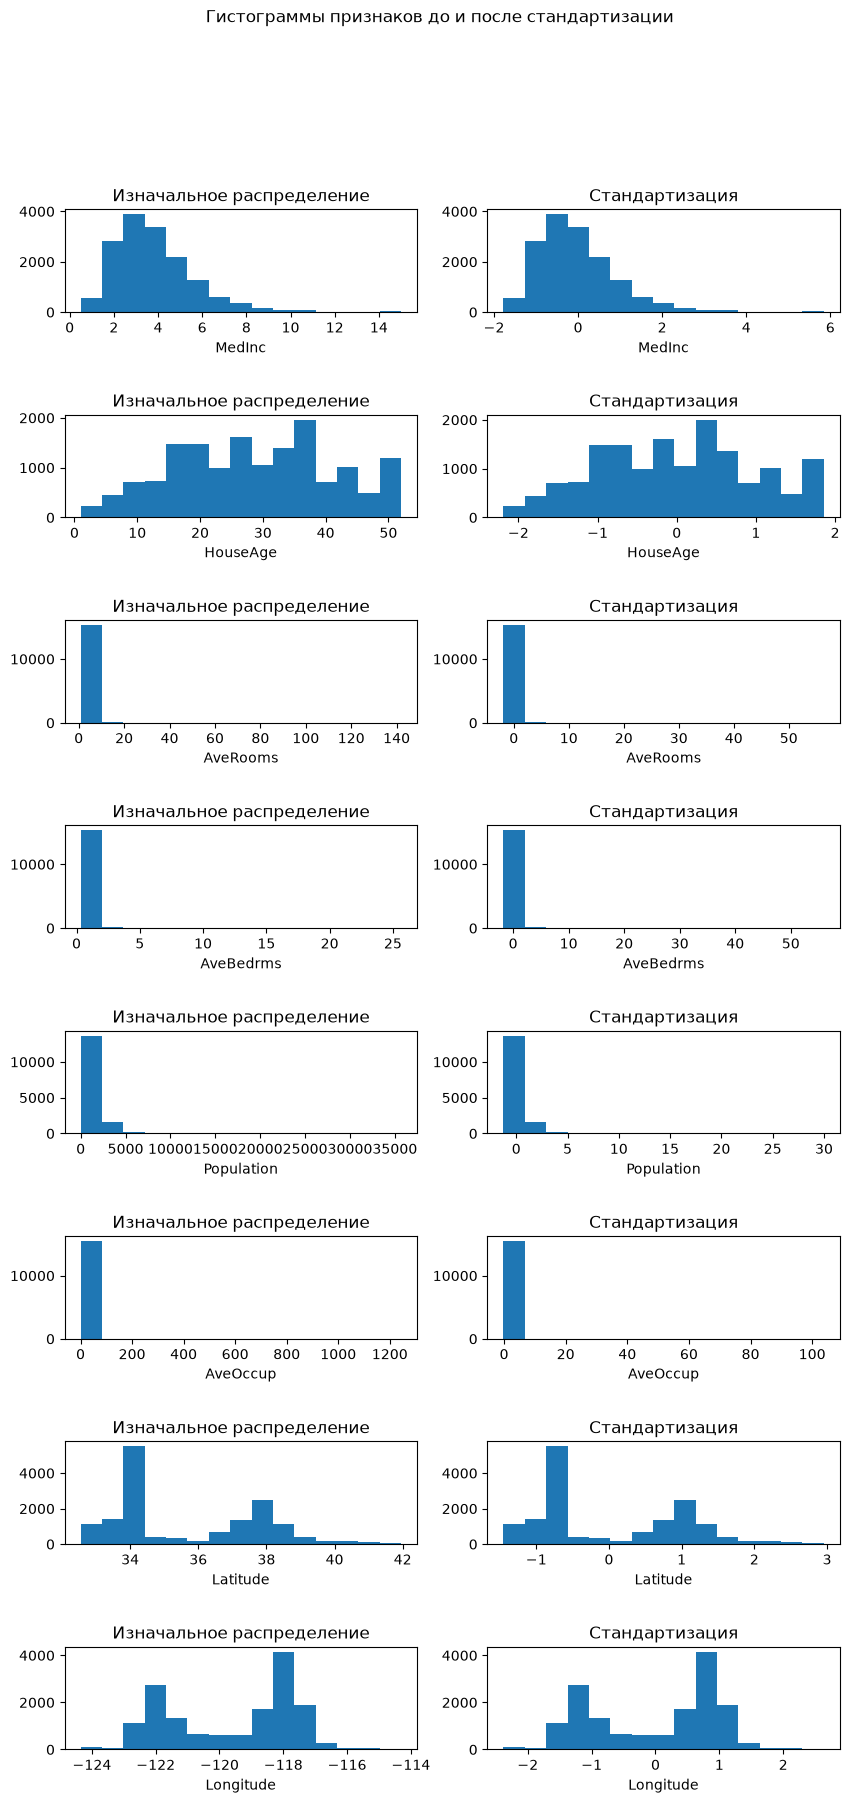

In [56]:
f, ax = plt.subplots(nrows = X_train.shape[1], ncols = 2, figsize=(10,20))
f.suptitle("Гистограммы признаков до и после стандартизации")
for i in range(0,X_train.shape[1]):
    ax[i][0].hist(X_train[:, i], bins = 15)
    ax[i][0].set_title('Изначальное распределение')
    ax[i][0].set_xlabel(data.feature_names[i])
    
    ax[i][1].hist(X_train_sc[:, i], bins = 15)
    ax[i][1].set_title('Стандартизация')
    ax[i][1].set_xlabel(data.feature_names[i])
f.subplots_adjust(hspace=1)

plt.show()

### 7. Обучите модель линейной регрессии для предсказания медианной стоимости дома в округах Калифорнии на стандартизированных данных. Выведите полученные коэффициенты  гиперплоскости. Напечатайте рядом название признака и соответствующий ему вес. Сделайте вывод о значимости признаков. 

In [57]:
model_sc = LinearRegression()
model_sc.fit(X_train_sc, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](8,)","[ 0.85, 0.12,-0.3 ,...,-0.04,-0.89,-0.87]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,2.07
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,8
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(8)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](8,)","[176.97,170.41,140.36,...,100.95, 35.55, 26.98]"


In [58]:
model_sc.intercept_, model_sc.coef_

(np.float64(2.0703489205424743),
 array([ 0.85210815,  0.12065533, -0.30210555,  0.34860575, -0.00164465,
        -0.04116356, -0.89314697, -0.86784046]))

In [59]:
for i, coef in enumerate(model_sc.coef_):
    print(f'{i}: {data.feature_names[i]}: {coef}')

0: MedInc: 0.852108146777998
1: HouseAge: 0.12065532544175885
2: AveRooms: -0.3021055541018938
3: AveBedrms: 0.3486057520116918
4: Population: -0.0016446540574329138
5: AveOccup: -0.04116356309507082
6: Latitude: -0.8931469709006682
7: Longitude: -0.8678404634642941


### 8. Обучите модель линейной регрессии на стандартизированных данных с применением конвейера, используя класс Pipeline. Выведите полученные коэффициенты гиперплоскости. Сделайте предсказание на стандартизированных тестовых данных. Вычислите метрики коэффициент детерминации и ошибку RMSE. Убедитесь, что они получились те же, что и без применения конвейера.

In [60]:
pipe = Pipeline(steps=[('scaler', StandardScaler()), ('model', LinearRegression())])
pipe.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,8
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value
"mean_ mean_: ndarray of shape (n_features,) or NoneThe mean value for each feature in the training set.Equal to ``None`` when ``with_mean=False`` and ``with_std=False``.","ndarray[float64](8,)","[ 3.88, 28.6 , 5.44,..., 3.11, 35.65,-119.58]"


In [61]:
pipe.named_steps['model'].intercept_, pipe.named_steps['model'].coef_

(np.float64(2.0703489205424743),
 array([ 0.85210815,  0.12065533, -0.30210555,  0.34860575, -0.00164465,
        -0.04116356, -0.89314697, -0.86784046]))

In [62]:
y_test_pred_pipe = pipe.predict(X_test)
y_test_pred_pipe

array([0.72412832, 1.76677807, 2.71151581, ..., 1.72382152, 2.34689276,
       3.52917352], shape=(5160,))

In [63]:
r2 = metrics.r2_score(y_test, y_test_pred_pipe)
r2

0.5910509795491351

In [64]:
rmse = metrics.root_mean_squared_error(y_test, y_test_pred_pipe)
rmse

0.7356145375446769

### 9. Обучите модель линейной регрессии на стандартизированных данных с применением конвейера, используя класс make_pipeline. Выведите полученные коэффициенты гиперплоскости. Сделайте предсказание на стандартизированных тестовых данных и вычислите метрики коэффициент детерминации и ошибку RMSE.

Указание: Конвейер в этом случае строится без указания имён шагов pipe_quick = make_pipeline(StandardScaler(), LinearRegression()). Для того, чтобы посмотреть имена шагов, используйте pipe_quick.steps.

In [65]:
pipe_quick = make_pipeline(StandardScaler(), LinearRegression())
pipe_quick.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('linearregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,8
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value
"mean_ mean_: ndarray of shape (n_features,) or NoneThe mean value for each feature in the training set.Equal to ``None`` when ``with_mean=False`` and ``with_std=False``.","ndarray[float64](8,)","[ 3.88, 28.6 , 5.44,..., 3.11, 35.65,-119.58]"


In [66]:
pipe_quick.steps

[('standardscaler', StandardScaler()),
 ('linearregression', LinearRegression())]

In [67]:
pipe_quick.named_steps['linearregression'].intercept_

np.float64(2.0703489205424743)

In [68]:
pipe_quick.named_steps['linearregression'].coef_

array([ 0.85210815,  0.12065533, -0.30210555,  0.34860575, -0.00164465,
       -0.04116356, -0.89314697, -0.86784046])

In [69]:
y_test_pred_pipe_qck = pipe_quick.predict(X_test)

In [70]:
r2_qck = metrics.r2_score(y_test, y_test_pred_pipe_qck)
r2_qck

0.5910509795491351

In [71]:
rmse_qck = metrics.root_mean_squared_error(y_test, y_test_pred_pipe_qck)
rmse_qck

0.7356145375446769

### 10. Обучите модель линейной регрессии на масштабированных данных методом min-max нормализации в диапазоне от -1 до 1 с применением конвейера, используя класс Pipeline. Сделайте предсказание на масштабированных тестовых данных. Вычислите метрики коэффициент детерминации и ошибку RMSE. Улучшились ли при этом значения метрик?

In [72]:
pipe2 = Pipeline(steps=[('scaler', MinMaxScaler(feature_range=(-1, 1))), ('model', LinearRegression())])

In [73]:
pipe2.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,8
,"feature_range feature_range: tuple (min, max), default=(0, 1)Desired range of transformed data.","(-1, ...)"
,"copy copy: bool, default=TrueSet to False to perform inplace row normalization and avoid acopy (if the input is already a numpy array).",True
,"clip clip: bool, default=FalseSet to True to clip transformed values of held-out data toprovided `feature_range`.Since this parameter will clip values, `inverse_transform` may notbe able to restore the original data... note:: Setting `clip=True` does not prevent feature drift (a distribution shift between training and test data). The transformed values are clipped to the `feature_range`, which helps avoid unintended behavior in models sensitive to out-of-range inputs (e.g. linear models). Use with care, as clipping can distort the distribution of test data... versionadded:: 0.24",False
Name,Type,Value
"data_max_ data_max_: ndarray of shape (n_features,)Per feature maximum seen in the data.. versionadded:: 0.17 *data_max_*","ndarray[float64](8,)","[ 15. , 52. , 141.91,...,1243.33, 41.95,-114.31]"


In [74]:
y_test_pred_pipe2 = pipe2.predict(X_test)
y_test_pred_pipe2

array([0.72412832, 1.76677807, 2.71151581, ..., 1.72382152, 2.34689276,
       3.52917352], shape=(5160,))

In [75]:
r2_pipe2 = metrics.r2_score(y_test, y_test_pred_pipe2)
r2_pipe2, r2, r2_qck

(0.5910509795491354, 0.5910509795491351, 0.5910509795491351)

In [76]:
rmse_pipe2 = metrics.root_mean_squared_error(y_test, y_test_pred_pipe2)
rmse_pipe2, rmse, rmse_qck

(0.7356145375446766, 0.7356145375446769, 0.7356145375446769)